## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Nguyen

**Date:** 10-12-26

In [140]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import seaborn as sns

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
---

Answer: As noise goes up, each cluster gets more and more spread out. Initially when the noise was 0.125 the clusters were easily seperatable, but as the noise grew the points spread out until I could no longer distinguish between the groups. 

<Axes: xlabel='x1', ylabel='x2'>

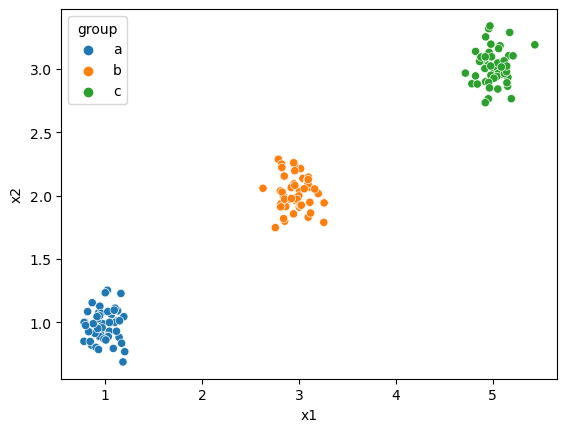

In [141]:
df0_125_scatter = sns.scatterplot(data = df0_125, x = "x1", y = "x2", hue = "group")
df0_125_scatter 

<Axes: xlabel='x1', ylabel='x2'>

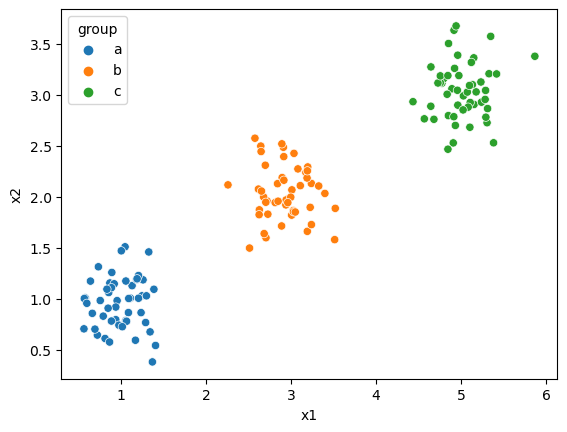

In [142]:
df0_25_scatter = sns.scatterplot(data = df0_25, x = "x1", y = "x2", hue = "group")
df0_25_scatter 

<Axes: xlabel='x1', ylabel='x2'>

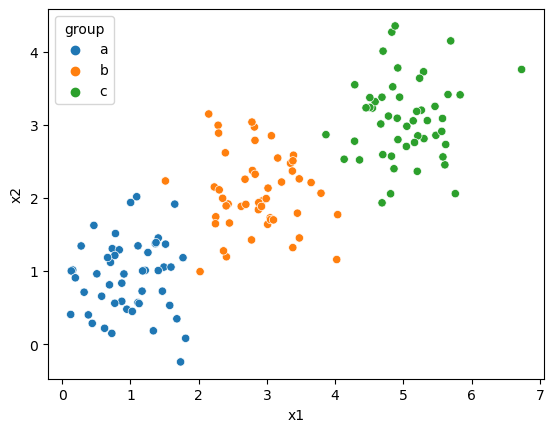

In [143]:
df0_5_scatter = sns.scatterplot(data = df0_5, x = "x1", y = "x2", hue = "group")
df0_5_scatter 

<Axes: xlabel='x1', ylabel='x2'>

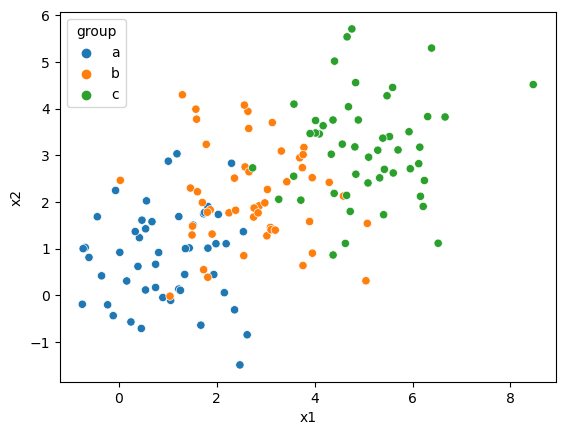

In [144]:
df1_0_scatter = sns.scatterplot(data = df1_0, x = "x1", y = "x2", hue = "group")
df1_0_scatter 

<Axes: xlabel='x1', ylabel='x2'>

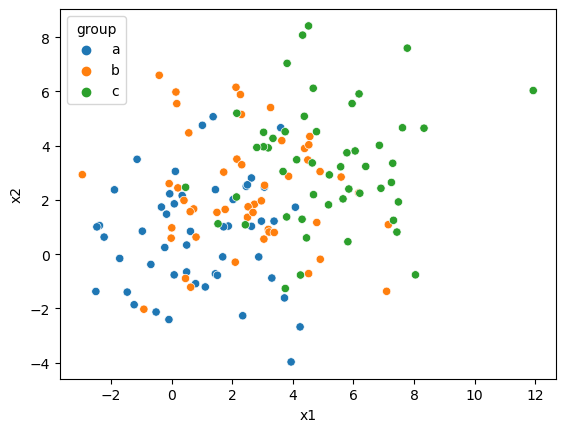

In [145]:
df2_0_scatter = sns.scatterplot(data = df2_0, x = "x1", y = "x2", hue = "group")
df2_0_scatter 

3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
---
Answer: As the noise grew, distinguishing the elbow became more and more difficult. It was very clear because of the sudden drop off into an almost flat curve when noise was 0.125, but that sharp turn into a flat curve became more and more subtle. As a result, my ability to definitively select a $k$ became harder as well.

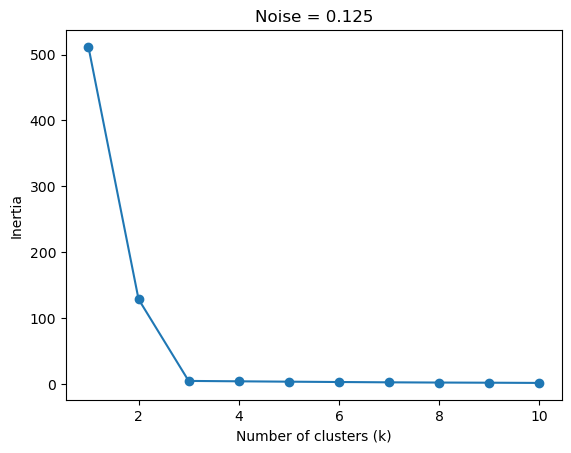

In [146]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(df0_125[["x1", "x2"]])
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = 0.125")
plt.show()

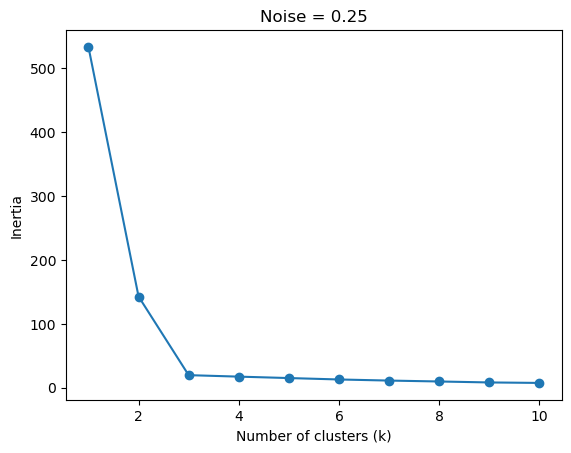

In [147]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(df0_25[["x1", "x2"]])
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = 0.25")
plt.show()

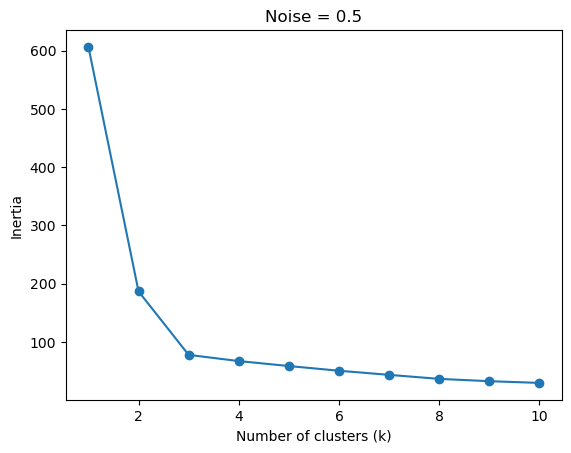

In [148]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(df0_5[["x1", "x2"]])
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = 0.5")
plt.show()

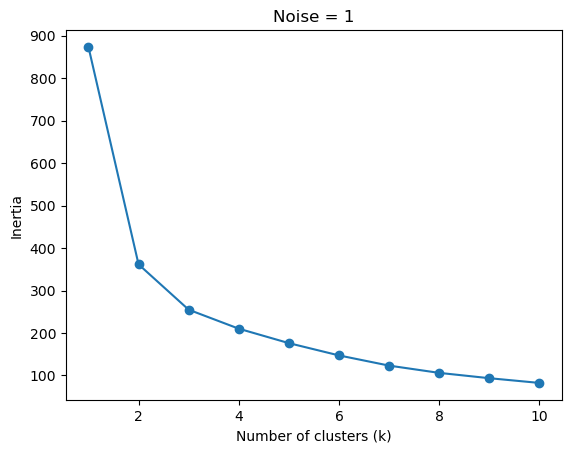

In [149]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(df1_0[["x1", "x2"]])
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = 1")
plt.show()

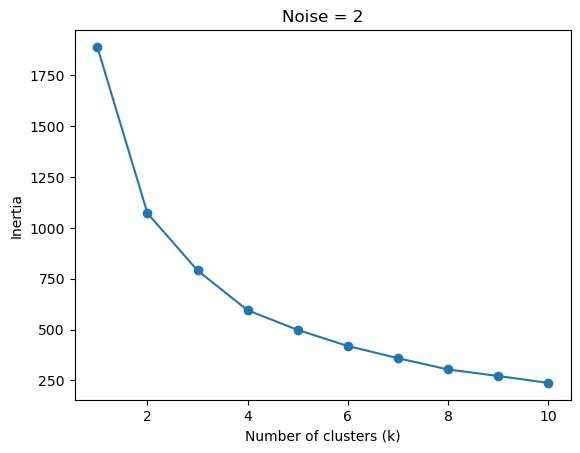

In [150]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(df2_0[["x1", "x2"]])
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = 2")
plt.show()

4. Explain the intuition of the elbow, using this numerical simulation as an example.
---
Answer: The elbow is where adding more clusters stops reducing inertia by a lot. In this simulation, inertia drops a lot until there are three clusters, then the graph starts to flatten because adding more clusters barely helps. As noise increases, the points spread into each other and the groups become harder to distinguish, so the elbow becomes less obvious and choosing a good $k$ becomes harder

# Question 2


In [151]:
SIPRI_df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
filtered_SIPRI_df = SIPRI_df[SIPRI_df["Year"] == 2020].dropna()
print(filtered_SIPRI_df.info())
print(filtered_SIPRI_df.describe())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 9.2+ KB
None
             index    Year  Spending (2020 USD)  Percent of GDP  \
count   148.000000   148.0           148.000000      148.000000   
mean   2831.256757  2020.0         13153.747670        0.019619   
std    1654.299355     0.0         68005.236120        0.015033   
min      3

2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
---
Many of the points look almost like a vertical line because the US spends so much more overall that the other countries get squeezed together on the graph. The groups mainly differ in spending per capita, while the US is the green point in its own cluster. Its total spending is much higher, and its spending per capita is also high, though it is not the highest.

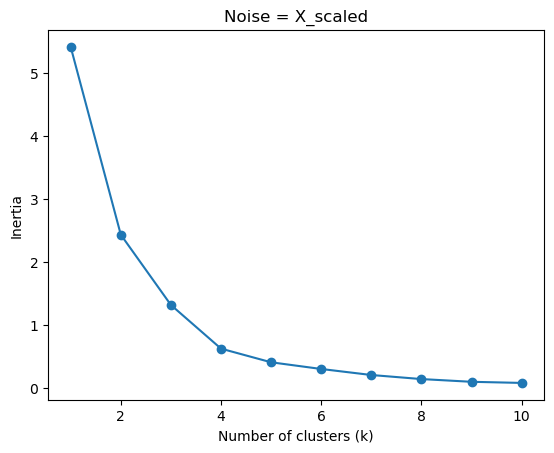

In [152]:
cols = ["Spending (2020 USD)", "Spending per Capita"]

X = filtered_SIPRI_df[cols]
X_scaled = (X - X.min()) / (X.max() - X.min())

inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = X_scaled")
plt.show()

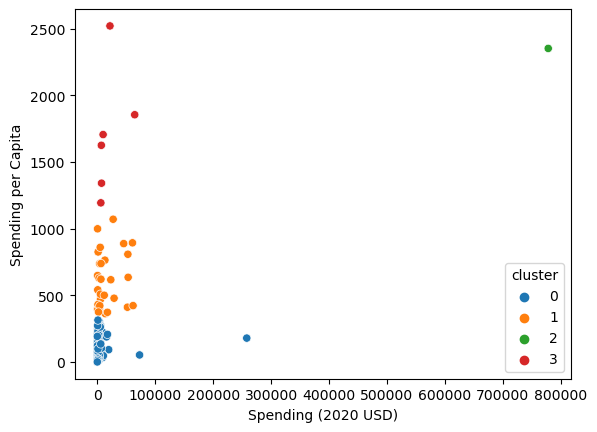

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     111.0    4859.185065  25405.739131       8.622460   
1                      30.0   17077.591354  20583.053357     405.790494   
2                       1.0  778397.200000           NaN  778397.200000   
3                       6.0   19443.362047  22861.507114    6095.708713   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           130.010211     382.464677    2297.032353  257973.429834   
1          2294.039665    5857.060906   26296.001003   61712.537169   
2        778397.200000  778397.200000  778397.200000  778397.200000   
3          7023.251766    8624.225729   18857.070183   64558.400000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                     111.0    80.061470   83.501824     0.580129   
1                      30.0   607.478618  206.928757   362.467076   
2                       1.0  2351.631858         NaN  2351.631858   
3                       6.0  1706.721916  466.375705  1193.598730   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0          14.880549    47.056944   125.387558   314.201312  
1         422.208252   579.004604   757.328513  1070.623322  
2        2351.631858  2351.631858  2351.631858  2351.631858  
3        1412.083201  1665.447478  1817.219993  2520.398541

In [153]:
model = KMeans(n_clusters=4, random_state=100, n_init=10)
filtered_SIPRI_df["cluster"] = model.fit_predict(X_scaled)

sns.scatterplot(
    data=filtered_SIPRI_df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster",
    palette="tab10"
)
plt.show()

filtered_SIPRI_df.groupby("cluster")[cols].describe()

3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
---
The graph had a less obvious elbow, so I decided to try using k = 3 for the scatterplot. The scatterplot shows a positive relationship: countries that spend a larger percentage of their budget on their military also have a higher percentage of GDP. The groups roughly separate into low, medium, and high spending shares. Compared to part 2, these groups show how much each country is spending towards their military, rather than total spending.

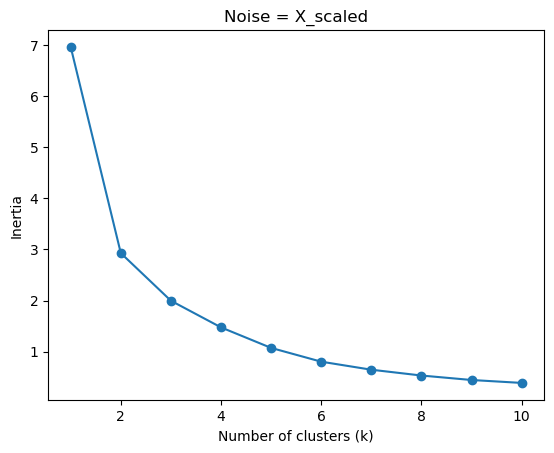

In [154]:
cols = ["Percent of Government Spending", "Percent of GDP"]

X = filtered_SIPRI_df[cols]
X_scaled = (X - X.min()) / (X.max() - X.min())

inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = X_scaled")
plt.show()

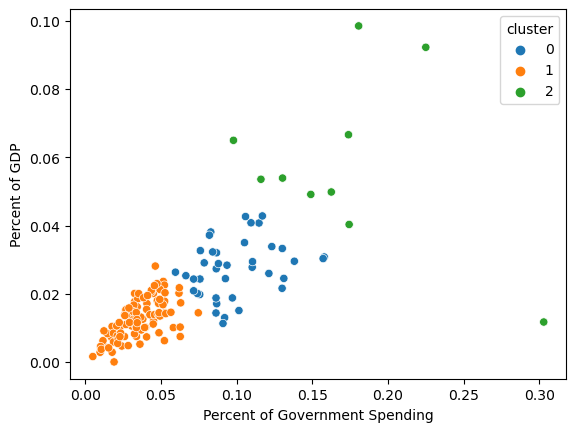

Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 99.0  0.035777  0.014549  0.004896   
2                                 10.0  0.171289  0.058725  0.097882   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1        0.005681  0.000054  0.008393  0.013191  0.016752  0.028132  
2        0.024867  0.011742  0.049297  0.053729  0.066190  0.098470

In [155]:
model = KMeans(n_clusters=3, random_state=100, n_init=10)
filtered_SIPRI_df["cluster"] = model.fit_predict(X_scaled)

sns.scatterplot(
    data=filtered_SIPRI_df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster",
    palette="tab10"
)
plt.show()

filtered_SIPRI_df.groupby("cluster")[cols].describe()

4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
---
Using all four variables, I chose $k$ = 3 because the scree plot starts to flatten around there. Compared to part 2, the US is no longer in its own cluster and is now grouped with five other countries with high spending per capita. Compared to part 3, the groups now account for spending amounts as well as spending shares. The blue group generally has lower spending shares, the orange group has high spending per capita, and the green group has higher spending shares without especially high spending per capita. Some colors overlap in the graphs because each graph only shows two of the four variables used to form the clusters. The comparison with part 2 also reflects using three clusters instead of four.

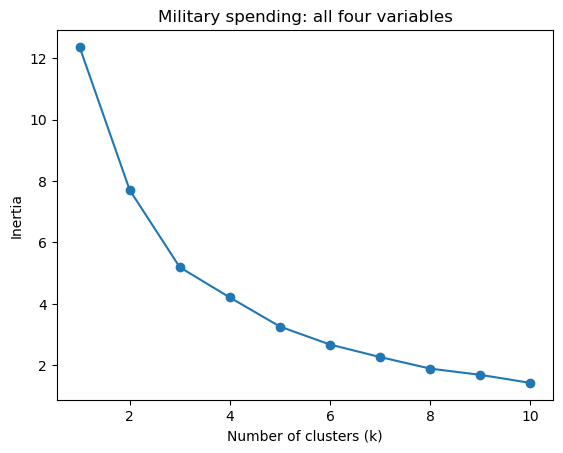

In [156]:
cols_all = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

X_all = filtered_SIPRI_df[cols_all]
X_all_scaled = (X_all - X_all.min()) / (X_all.max() - X_all.min())

inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_all_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Military spending: all four variables")
plt.show()

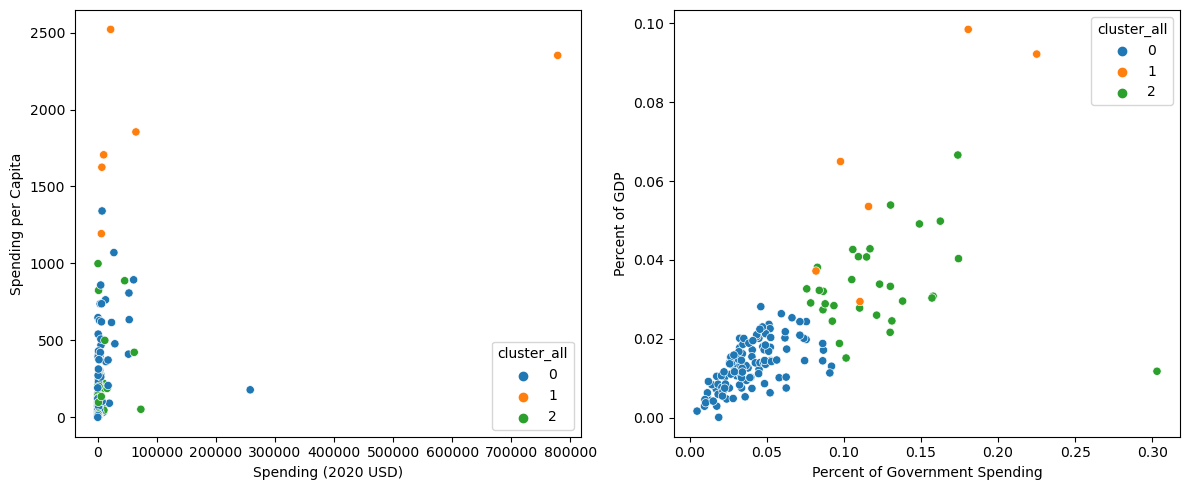

Spending (2020 USD)                                             \
                          count           mean            std          min   
cluster_all                                                                  
0                         111.0    7086.472777   26479.379918     8.622460   
1                           6.0  147964.582042  309635.189564  6095.708713   
2                          31.0    8786.086602   17901.909108   162.373364   

                                                                     \
                     25%           50%           75%            max   
cluster_all                                                           
0             130.010211    567.650747   3910.107493  257973.429834   
1            7700.424616  15897.570598  53872.942442  778397.200000   
2             467.787851   1404.787234   7739.166193   72937.064048   

            Spending per Capita               ...  \
                          count         mean  ...   
cluster_all                                   ...   
0                         111.0   196.926833  ...   
1                           6.0  1875.150751  ...   
2                          31.0   212.689100  ...   

            Percent of Government Spending           Percent of GDP            \
                                       75%       max          count      mean   
cluster_all                                                                     
0                                 0.050505  0.092044          111.0  0.013419   
1                                 0.164503  0.225050            6.0  0.062634   
2                                 0.134663  0.303027           31.0  0.033492   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_all                                                              
0            0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  
1            0.028275  0.029429  0.041272  0.059257  0.085398  0.098470  
2            0.011449  0.011742  0.027560  0.032024  0.040531  0.066600  

[3 rows x 32 columns]

,Country,cluster_all,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
5540,United States of America,1,778397.2,2351.631858,0.081976,0.037179


In [157]:

model = KMeans(n_clusters=3, random_state=100, n_init=10)
filtered_SIPRI_df["cluster_all"] = model.fit_predict(X_all_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=filtered_SIPRI_df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster_all",
    palette="tab10",
    ax=axes[0]
)

sns.scatterplot(
    data=filtered_SIPRI_df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster_all",
    palette="tab10",
    ax=axes[1]
)

plt.tight_layout()
plt.show()

display(filtered_SIPRI_df.groupby("cluster_all")[cols_all].describe())

display(
    filtered_SIPRI_df.loc[
        filtered_SIPRI_df["Country"] == "United States of America",
        ["Country", "cluster_all"] + cols_all
    ]
)

5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?
---
Yes, the $k$-MC algorithm helped me see that high total military spending doesn't always mean a country spends a high percentage of its GDP or government budget. In part 2 I could clearly see the US stood out in its own cluster, but in part 3 it grouped countries by their spending shares. Using all four variables showed how countries could have similar spending per capita but different shares. 

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 41ab451ff4044dec5c477d053d1737682846b525
- **AI tool and model used:** GPT 6.1 sol

### *Prompts used

1. Review notebook.ipynb and help me complete Phase 2 for Q1 and Q2. Keep Phase 1 unchanged. Check the code, plots, and interpretations for accuracy and completeness. Give me a concise numbered list of proposed changes that I can paste into “AI-proposed changes.” For each change, explain why it helps and how I can verify it. Then provide the revised code and explanations separately for Phase 2, keeping the explanations close to my writing style. Leave the evaluation decisions and reflection for me to write.
2. Here is is my reasoning for each of your points. read thorugh them, suggest any changes or if you agree, please help me improve my phase 1 change by change. 

### *AI-proposed changes


1. Compare Q1 plots using shared scatterplot axes and raw and relative scree curves. This makes noise levels easier to compare. Verify 150 points per dataset and relative inertia starting at 1.
2. Clarify that Q1 has three generating groups, but high noise weakens the elbow. This avoids overstating what k-means recovers. Verify the sharp low-noise elbow against the smoother high-noise curves.
3. Check Q2 cleaning, exclude identifiers, and format proportions as percentages. This prevents inappropriate features and confusing units. Verify 148 unique countries, finite numeric values, and normalized ranges from 0 to 1.
4. Preserve separate Q2 cluster columns and show inertia reductions for k = 4, 3, and 3. This supports the choices without claiming a unique optimum. Verify the reductions around each chosen k.
5. Add cluster sizes, describe tables, country lists, and US lookups. This makes interpretations verifiable without relying on colors. Verify sizes total 148 and the US is alone in the amount model but among six countries in the four-variable model.
6. Add membership cross-tabulations and an all-variable k = 4 comparison. This helps distinguish feature changes from changes in k. Verify the US still joins the same five countries at k = 4, and compare cluster means and memberships.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / `modify` / reject | For the scree plots, I do agree with this. Having them overlap may make it a bit easier to compare. But for the scatter plots, since theres so many points i think overlapping them would actually make it harder to interpret. Instead of having a shared graph for them I could just have them side by side instead of a new one in each cell to compare, but I think this point would apply better for scree plots. |
| 2 | `Accept` / modify / reject | This makes sense, I think it would let the viewers have a better understanding of the data, and its a good thing to verify.  |
| 3 | `Accept` / modify / reject | I think this is just telling me to check and verify all the cleaning in Q2, so I can do that. |
| 4 | Accept / `modify` / reject | Also saying I should verify my k choices, and also have separate places where I explain why I chose those. I believe I already explained these, but I could add another section to explain it on a deeper level |
| 5 | Accept / `modify` / reject | Another thing saying I should just verify my choices and show evidence backing them up |
| 6 | Accept / modify / `reject` | not sure if this is needed for this assignment |



### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### Question 1

**1–2. Generate the datasets and compare their scatterplots.**

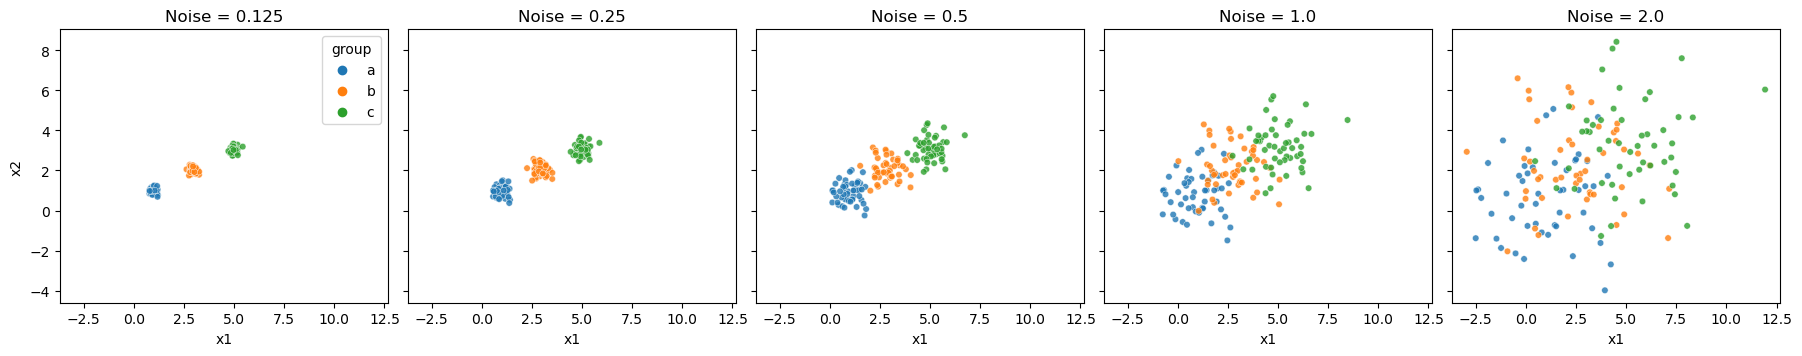

In [158]:
# Phase 2: Q1 data, generated the same way as Phase 1.
import numpy as np
import pandas as pd
import seaborn as sns

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.cluster import KMeans
from IPython.display import display

noise_datasets = {
    0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0
}
fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharex=True, sharey=True)
for ax, (noise, df) in zip(axes, noise_datasets.items()):
    assert len(df) == 150
    sns.scatterplot(data=df, x="x1", y="x2", hue="group",
                    hue_order=["a", "b", "c"], palette="tab10",
                    ax=ax, s=22, alpha=0.8, legend=(noise == 0.125))
    ax.set_title(f"Noise = {noise}")
    ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

Answer: As noise goes up, each cluster gets more and more spread out. Initially when the noise was 0.125 the clusters were easily separatable, but as the noise grew the points spread out until the groups became harder to distinguish. At 0.5 some points start to overlap, and at 1.0 and 2.0 the groups overlap much more. Having the scatterplots side by side with the same axis scales makes this easier to compare.

**3. Compare the scree curves.**

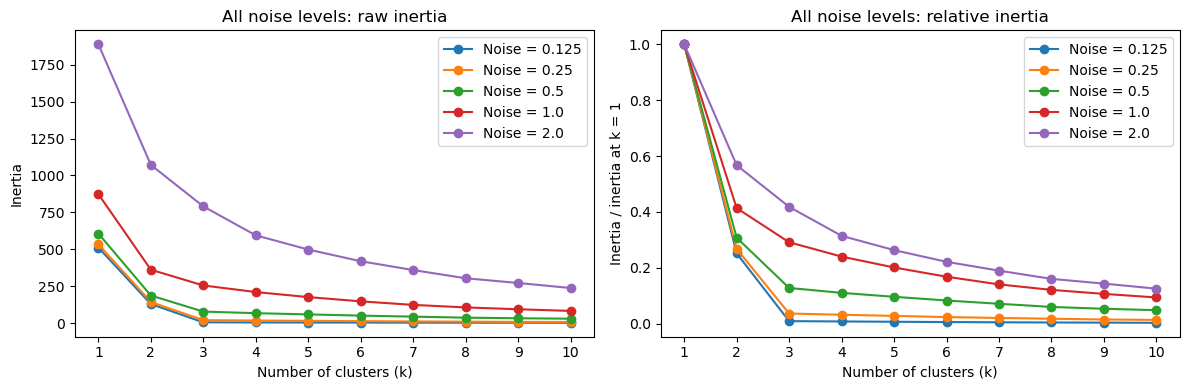

In [159]:
ks = range(1, 11)

def get_inertias(X):
    return np.array([
        KMeans(n_clusters=k, random_state=100, n_init=10).fit(X).inertia_
        for k in ks
    ])

q1_inertias = pd.DataFrame({
    noise: get_inertias(df[["x1", "x2"]])
    for noise, df in noise_datasets.items()
}, index=pd.Index(ks, name="k"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for noise in noise_datasets:
    values = q1_inertias[noise]
    axes[0].plot(ks, values, marker="o", label=f"Noise = {noise}")
    axes[1].plot(ks, values / values.iloc[0], marker="o", label=f"Noise = {noise}")
for ax in axes:
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(list(ks))
    ax.legend()
axes[0].set_title("All noise levels: raw inertia")
axes[0].set_ylabel("Inertia")
axes[1].set_title("All noise levels: relative inertia")
axes[1].set_ylabel("Inertia / inertia at k = 1")
assert np.allclose((q1_inertias / q1_inertias.iloc[0]).iloc[0], 1)
plt.tight_layout()
plt.show()

Answer: As the noise grew, distinguishing the elbow became more difficult. At low noise, there is a sharp turn into an almost flat curve after k = 3. At higher noise, that turn becomes more subtle, so selecting k becomes harder. The raw curves also show that higher noise leaves more variation within clusters. The relative curves start at 1 and make it easier to compare the shapes even though the raw inertia values are different.

**4. Explain the intuition of the elbow.**

Answer: The elbow is where adding more clusters stops reducing inertia by a lot. Inertia is the sum of squared distances between points and their assigned cluster centers. In this simulation there are three generating groups. With low noise, inertia drops a lot until there are three clusters, then the graph starts to flatten because extra clusters mostly split points that are already close together. As noise increases, the points spread into each other and extra centers can still reduce inertia by splitting up that spread. The elbow becomes less obvious, so knowing that three groups generated the data does not mean the graph will clearly select k = 3 at every noise level.

### Question 2

**1. Load and check the data.**

In [160]:
SIPRI_df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
filtered_SIPRI_df = SIPRI_df.loc[SIPRI_df["Year"] == 2020].dropna().copy()
cols_all = [
    "Spending (2020 USD)", "Spending per Capita",
    "Percent of Government Spending", "Percent of GDP"
]
assert len(filtered_SIPRI_df) == 148
assert filtered_SIPRI_df["Country"].is_unique
assert all(pd.api.types.is_numeric_dtype(filtered_SIPRI_df[c]) for c in cols_all)
assert np.isfinite(filtered_SIPRI_df[cols_all].to_numpy()).all()
assert (filtered_SIPRI_df[cols_all] >= 0).all().all()
assert filtered_SIPRI_df[cols_all[2:]].le(1).all().all()
print("Complete 2020 countries:", len(filtered_SIPRI_df))
filtered_SIPRI_df[cols_all].info()
display(filtered_SIPRI_df[cols_all].describe())

def minmax(X):
    ranges = X.max() - X.min()
    assert (ranges > 0).all()
    scaled = (X - X.min()) / ranges
    assert np.allclose(scaled.min(), 0)
    assert np.allclose(scaled.max(), 1)
    return scaled

# Show the evidence without manually counting points.
def cluster_evidence(label, cols):
    sizes = filtered_SIPRI_df.groupby(label).size().rename("Countries")
    assert sizes.sum() == 148
    display(sizes.to_frame())
    with pd.option_context("display.max_columns", None):
        display(filtered_SIPRI_df.groupby(label)[cols].describe())
    us = filtered_SIPRI_df.loc[
        filtered_SIPRI_df["Country"] == "United States of America",
        ["Country", label] + cols
    ]
    assert len(us) == 1
    display(us)
    us_cluster = us[label].iloc[0]
    print("Countries in the US cluster:",
          filtered_SIPRI_df.loc[filtered_SIPRI_df[label] == us_cluster, "Country"].tolist())

def scree_plot(X_scaled, title, chosen_k):
    values = get_inertias(X_scaled)
    plt.figure(figsize=(6, 4))
    plt.plot(ks, values, marker="o")
    plt.axvline(chosen_k, color="gray", linestyle="--", label=f"Chosen k = {chosen_k}")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Inertia")
    plt.title(title)
    plt.xticks(list(ks))
    plt.legend()
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame({"k": list(ks), "Inertia": values,
                          "Reduction from previous k": np.r_[np.nan, -np.diff(values)]}).round(4))

# Use cluster labels as categories so colors do not imply numerical ordering.
def cluster_scatter(ax, label, x, y):
    labels = sorted(filtered_SIPRI_df[label].unique())
    palette = dict(zip(labels, sns.color_palette("tab10", len(labels))))
    sns.scatterplot(data=filtered_SIPRI_df, x=x, y=y, hue=label,
                    hue_order=labels, palette=palette, ax=ax)
    us = filtered_SIPRI_df.loc[filtered_SIPRI_df["Country"] == "United States of America"].iloc[0]
    ax.annotate("US", (us[x], us[y]), xytext=(5, 5), textcoords="offset points")
    if x.startswith("Percent"):
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    if y.startswith("Percent"):
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

Complete 2020 countries: 148
<class 'pandas.core.frame.DataFrame'>
Int64Index: 148 entries, 32 to 5880
Data columns (total 4 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Spending (2020 USD)             148 non-null    float64
 1   Spending per Capita             148 non-null    float64
 2   Percent of Government Spending  148 non-null    float64
 3   Percent of GDP                  148 non-null    float64
dtypes: float64(4)
memory usage: 5.8 KB


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
count,148.000000,148.000000,148.000000,148.000000
mean,13153.747670,268.264494,0.061510,0.019619
std,68005.236120,430.434878,0.046207,0.015033
min,8.622460,0.580129,0.004896,0.000054
25%,204.877177,20.553464,0.031352,0.010413
50%,959.535443,81.506703,0.047402,0.015324
75%,5289.998320,326.267753,0.084681,0.024327
max,778397.200000,2520.398541,0.303027,0.098470


Answer: After selecting 2020 and dropping rows with missing values, I got 148 countries. The four spending variables are already numeric, and the checks found no duplicate countries or nonfinite values. No further numeric cleaning is needed for these rows. I leave out index, Year, and Country when clustering because they are identifiers or constant values.

The two columns named Percent contain proportions, so 0.037179 means about 3.72%. I keep the original values for normalization and format the plot axes as percentages. The describe tables still show the original proportions.

**2. Total spending and spending per capita.**

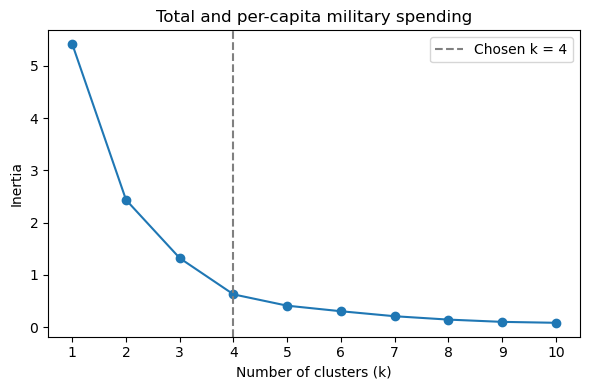

,k,Inertia,Reduction from previous k
0,1,5.4114,NaN
1,2,2.4353,2.9761
2,3,1.3218,1.1135
3,4,0.6294,0.6924
4,5,0.4131,0.2163
5,6,0.3070,0.1062
6,7,0.2116,0.0954
7,8,0.1471,0.0644
8,9,0.1039,0.0433
9,10,0.0860,0.0178


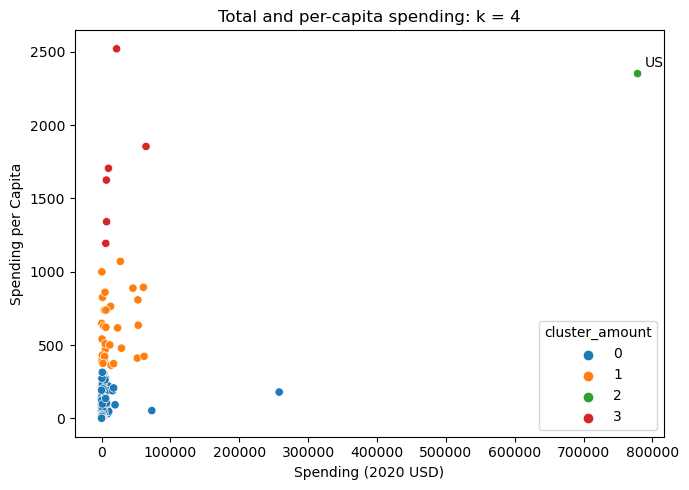

,Countries
cluster_amount,
0,111
1,30
2,1
3,6


Spending (2020 USD)                               \
                             count           mean           std   
cluster_amount                                                    
0                            111.0    4859.185065  25405.739131   
1                             30.0   17077.591354  20583.053357   
2                              1.0  778397.200000           NaN   
3                              6.0   19443.362047  22861.507114   

                                                                            \
                          min            25%            50%            75%   
cluster_amount                                                               
0                    8.622460     130.010211     382.464677    2297.032353   
1                  405.790494    2294.039665    5857.060906   26296.001003   
2               778397.200000  778397.200000  778397.200000  778397.200000   
3                 6095.708713    7023.251766    8624.225729   18857.070183   

                              Spending per Capita                           \
                          max               count         mean         std   
cluster_amount                                                               
0               257973.429834               111.0    80.061470   83.501824   
1                61712.537169                30.0   607.478618  206.928757   
2               778397.200000                 1.0  2351.631858         NaN   
3                64558.400000                 6.0  1706.721916  466.375705   

                                                                    \
                        min          25%          50%          75%   
cluster_amount                                                       
0                  0.580129    14.880549    47.056944   125.387558   
1                362.467076   422.208252   579.004604   757.328513   
2               2351.631858  2351.631858  2351.631858  2351.631858   
3               1193.598730  1412.083201  1665.447478  1817.219993   

                             
                        max  
cluster_amount               
0                314.201312  
1               1070.623322  
2               2351.631858  
3               2520.398541

,Country,cluster_amount,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


Countries in the US cluster: ['United States of America']
Highest spending per capita: Israel


In [161]:
cols_amount = ["Spending (2020 USD)", "Spending per Capita"]
X_amount_scaled = minmax(filtered_SIPRI_df[cols_amount])
scree_plot(X_amount_scaled, "Total and per-capita military spending", chosen_k=4)
model_amount = KMeans(n_clusters=4, random_state=100, n_init=10)
filtered_SIPRI_df["cluster_amount"] = model_amount.fit_predict(X_amount_scaled)
fig, ax = plt.subplots(figsize=(7, 5))
cluster_scatter(ax, "cluster_amount", *cols_amount)
ax.set_title("Total and per-capita spending: k = 4")
plt.tight_layout()
plt.show()
cluster_evidence("cluster_amount", cols_amount)
print("Highest spending per capita:",
      filtered_SIPRI_df.loc[filtered_SIPRI_df["Spending per Capita"].idxmax(), "Country"])

Answer: I chose k = 4 because the scree plot becomes much flatter after that point. Going from three to four clusters reduces inertia by about 0.692, while going from four to five reduces it by only about 0.216. This supports four as a reasonable choice, though the elbow does not prove there is one uniquely optimal k.

Many of the points look almost like a vertical line because the US spends so much more overall that the other countries get squeezed together on the graph. The groups mainly differ in spending per capita. Cluster 0 has 111 countries with low average spending per capita, cluster 1 has 30 countries with higher spending per capita, and cluster 3 has six countries with especially high spending per capita. The US is alone in cluster 2. Its total spending is much higher, and its spending per capita is also high, though Israel has the highest spending per capita. The cluster counts and US lookup back up what the plot shows. Cluster numbers are just labels, not rankings.

**3. Government spending share and GDP share.**

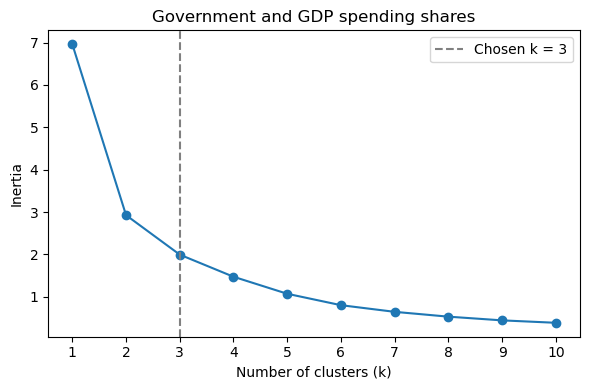

,k,Inertia,Reduction from previous k
0,1,6.9609,NaN
1,2,2.9274,4.0335
2,3,1.9958,0.9316
3,4,1.4745,0.5213
4,5,1.0728,0.4017
5,6,0.8033,0.2694
6,7,0.6462,0.1571
7,8,0.5325,0.1138
8,9,0.4450,0.0875
9,10,0.3877,0.0573


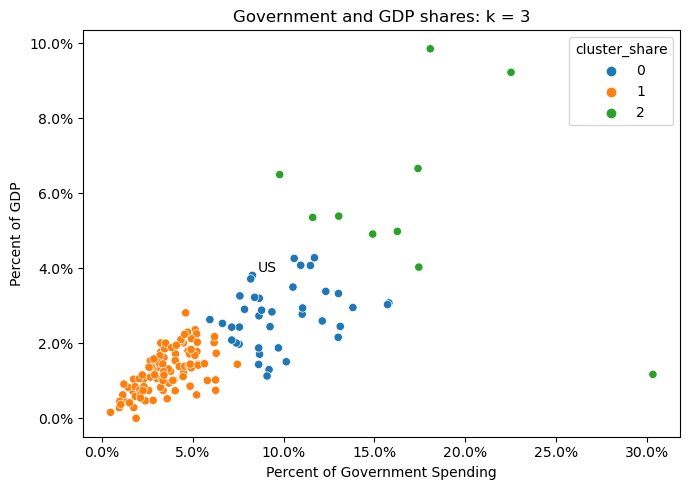

,Countries
cluster_share,
0,39
1,99
2,10


Percent of Government Spending                                \
                                       count      mean       std       min   
cluster_share                                                                
0                                       39.0  0.098683  0.024125  0.059520   
1                                       99.0  0.035777  0.014549  0.004896   
2                                       10.0  0.171289  0.058725  0.097882   

                                                      Percent of GDP  \
                    25%       50%       75%       max          count   
cluster_share                                                          
0              0.082430  0.092044  0.112633  0.157918           39.0   
1              0.025921  0.034261  0.047402  0.074624           99.0   
2              0.135010  0.168248  0.179081  0.303027           10.0   

                                                                           \
                   mean       std       min       25%       50%       75%   
cluster_share                                                               
0              0.027412  0.008191  0.011317  0.021254  0.027781  0.032461   
1              0.012664  0.005681  0.000054  0.008393  0.013191  0.016752   
2              0.058071  0.024867  0.011742  0.049297  0.053729  0.066190   

                         
                    max  
cluster_share            
0              0.042810  
1              0.028132  
2              0.098470

,Country,cluster_share,Percent of Government Spending,Percent of GDP
5540,United States of America,0,0.081976,0.037179


Countries in the US cluster: ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']


In [162]:
cols_share = ["Percent of Government Spending", "Percent of GDP"]
X_share_scaled = minmax(filtered_SIPRI_df[cols_share])
scree_plot(X_share_scaled, "Government and GDP spending shares", chosen_k=3)
model_share = KMeans(n_clusters=3, random_state=100, n_init=10)
filtered_SIPRI_df["cluster_share"] = model_share.fit_predict(X_share_scaled)
fig, ax = plt.subplots(figsize=(7, 5))
cluster_scatter(ax, "cluster_share", *cols_share)
ax.set_title("Government and GDP shares: k = 3")
plt.tight_layout()
plt.show()
cluster_evidence("cluster_share", cols_share)

Answer: The graph had a less obvious elbow, so I decided to keep k = 3 for the scatterplot. Inertia drops from about 6.961 at k = 1 to 2.927 at k = 2 and 1.996 at k = 3. The next reduction is smaller, to about 1.475 at k = 4. Three gives a useful summary of the spending shares, but other nearby choices are also possible.

The scatterplot shows a positive relationship: countries that spend a larger percentage of their government budget on their military generally also spend a higher percentage of GDP. The groups roughly separate into low, medium, and high average spending shares. Cluster 1 has 99 countries with lower shares, cluster 0 has 39 with medium shares, and cluster 2 has 10 with higher shares. The US is in cluster 0, with about 8.20% of government spending and 3.72% of GDP. Compared to part 2, these groups show spending relative to each country's budget and economy, rather than the total amount spent.

**4. All four numeric variables.**

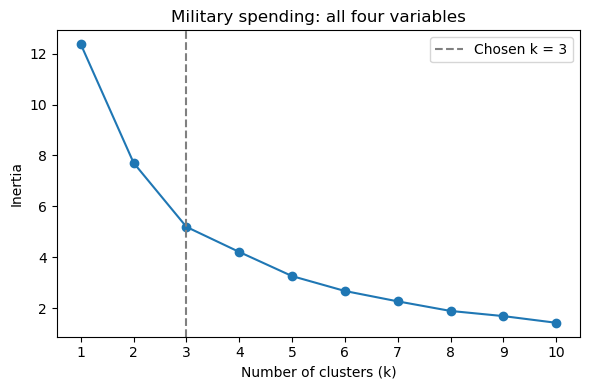

,k,Inertia,Reduction from previous k
0,1,12.3724,NaN
1,2,7.7096,4.6628
2,3,5.1926,2.5170
3,4,4.2070,0.9856
4,5,3.2582,0.9488
5,6,2.6727,0.5855
6,7,2.2652,0.4075
7,8,1.8886,0.3766
8,9,1.6859,0.2027
9,10,1.4227,0.2632


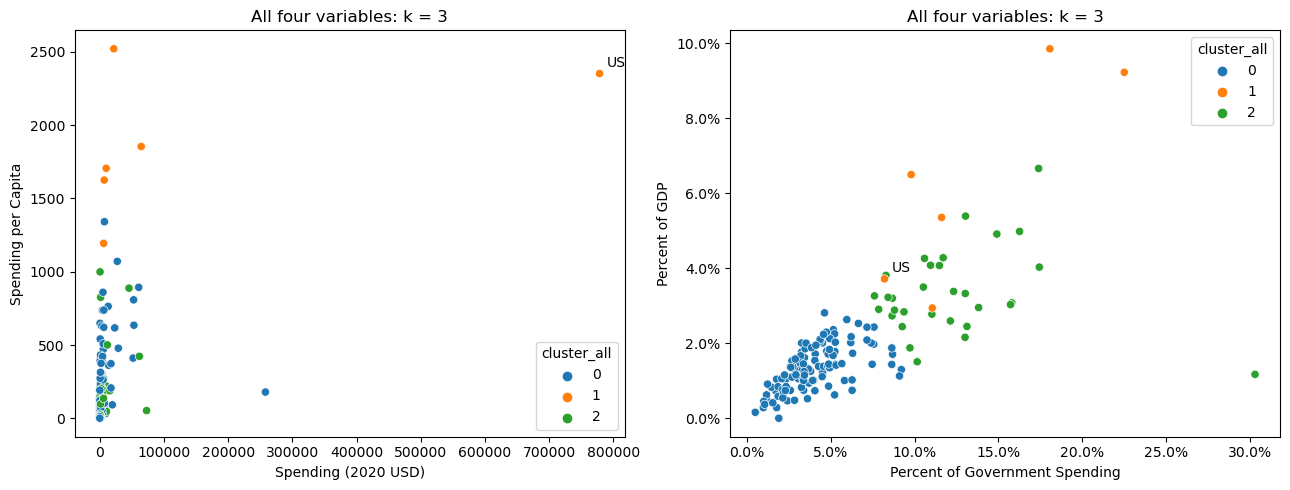

,Countries
cluster_all,
0,111
1,6
2,31


Spending (2020 USD)                                             \
                          count           mean            std          min   
cluster_all                                                                  
0                         111.0    7086.472777   26479.379918     8.622460   
1                           6.0  147964.582042  309635.189564  6095.708713   
2                          31.0    8786.086602   17901.909108   162.373364   

                                                                     \
                     25%           50%           75%            max   
cluster_all                                                           
0             130.010211    567.650747   3910.107493  257973.429834   
1            7700.424616  15897.570598  53872.942442  778397.200000   
2             467.787851   1404.787234   7739.166193   72937.064048   

            Spending per Capita                                        \
                          count         mean         std          min   
cluster_all                                                             
0                         111.0   196.926833  267.788506     0.580129   
1                           6.0  1875.150751  489.800206  1193.598730   
2                          31.0   212.689100  257.841988    18.297119   

                                                                 \
                     25%          50%          75%          max   
cluster_all                                                       
0              14.880549    67.083417   295.296094  1341.058851   
1            1645.301864  1780.059564  2227.318999  2520.398541   
2              46.485917   135.459845   217.333791   998.966186   

            Percent of Government Spending                                \
                                     count      mean       std       min   
cluster_all                                                                
0                                    111.0  0.040350  0.019320  0.004896   
1                                      6.0  0.135351  0.055392  0.081976   
2                                     31.0  0.122985  0.043927  0.076005   

                                                    Percent of GDP            \
                  25%       50%       75%       max          count      mean   
cluster_all                                                                    
0            0.026712  0.037952  0.050505  0.092044          111.0  0.013419   
1            0.101034  0.113271  0.164503  0.225050            6.0  0.062634   
2            0.093093  0.114776  0.134663  0.303027           31.0  0.033492   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_all                                                              
0            0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  
1            0.028275  0.029429  0.041272  0.059257  0.085398  0.098470  
2            0.011449  0.011742  0.027560  0.032024  0.040531  0.066600

,Country,cluster_all,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
5540,United States of America,1,778397.2,2351.631858,0.081976,0.037179


Countries in the US cluster: ['Israel', 'Kuwait', 'Oman', 'Saudi Arabia', 'Singapore', 'United States of America']


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster_all,,,,
0,7086.472777,196.926833,0.040350,0.013419
1,147964.582042,1875.150751,0.135351,0.062634
2,8786.086602,212.689100,0.122985,0.033492


In [163]:
X_all_scaled = minmax(filtered_SIPRI_df[cols_all])
scree_plot(X_all_scaled, "Military spending: all four variables", chosen_k=3)
model_all = KMeans(n_clusters=3, random_state=100, n_init=10)
filtered_SIPRI_df["cluster_all"] = model_all.fit_predict(X_all_scaled)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cluster_scatter(axes[0], "cluster_all", *cols_amount)
cluster_scatter(axes[1], "cluster_all", *cols_share)
for ax in axes:
    ax.set_title("All four variables: k = 3")
plt.tight_layout()
plt.show()
cluster_evidence("cluster_all", cols_all)
display(filtered_SIPRI_df.groupby("cluster_all")[cols_all].mean())

Answer: Using all four variables, I chose k = 3 because the scree plot starts to flatten around there. Going from two to three clusters reduces inertia by about 2.517, compared to about 0.986 from three to four. This makes three a reasonable choice, though the curve still continues downward.

Compared to part 2, the US is no longer in its own cluster and is now grouped with five other countries with high spending per capita: Israel, Kuwait, Oman, Saudi Arabia, and Singapore. The counts show 111 countries in cluster 0, six in cluster 1, and 31 in cluster 2. Compared to part 3, the groups now account for spending amounts as well as spending shares. Cluster 0 generally has lower spending shares, cluster 1 has especially high spending per capita and higher average spending shares, and cluster 2 has higher spending shares without especially high spending per capita.

Some colors overlap in the graphs because each graph only shows two of the four variables used to form the clusters. The comparison with part 2 also reflects using three clusters instead of four, so I cannot attribute every membership change only to adding the variables.

**5. Did k-means find useful patterns?**

Answer: Yes, the k-means algorithm helped me see that high total military spending doesn't always mean a country spends a high percentage of its GDP or government budget. In part 2 I could clearly see the US stood out in its own cluster, but in part 3 countries were grouped by their spending shares. Using all four variables showed how spending amounts and spending shares combine to form different groups. These patterns describe the countries with complete data in 2020, and do not explain why countries spend that way.

### *Reflection on AI assistance
In your own words without generative AI.

The main improvements were the suggestions of putting all scree plots on a shared plot so that it was easier to inspect and compare them. Putting them in separate plots made it harder to distinguish between them, but once they were overlapped it became clear what the differences were. I noticed that this time the AI proposed a lot of double-checking and verifying rather than trying to improve my solution, though. This could be looked at as a limitation, but it also depends on how much correction my original solution needed. If it truly did not need much correction and just verification, then this is mainly an improvement. In my prompt I asked for ways I could verify the final solution, so I followed those ways as well but also ensured that the code still ran correctly, all the graphs solutions matched my previous ones when it should have, and that the overall results matched. I had two remaining concerns, the AI actually tried editing it for me at first, and I had to ask it to revert all the changes and wait for my approval. Another concern I had was that choosing $k$ from an elbow is still subjective, especially when the clusters overlap.   